# Early classification pada light curve dengan fitur turunan

Notebook ini menguji kemampuan model memprediksi kelas dari evaluasi prefix temporal berbasis jumlah detection. Model tidak dilatih ulang: checkpoint fitur turunan single-seed digunakan untuk menguji 6, 10, 15, 20, 30, dan seluruh detection valid. Objek yang memiliki detection lebih sedikit dari threshold dikeluarkan dan jumlah objek valid dilaporkan.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from alerce_classifier.models import HybridCNNGRU, CNNClassifier, GRUClassifier
from alerce_classifier.training.loop import (
    evaluate_detection_prefixes, load_split, make_loader, evaluate,
)

import alerce_classifier
REPO_ROOT = Path(alerce_classifier.__file__).resolve().parents[2]
DATA_DIR = REPO_ROOT / 'data' / 'alerce_ztf_lc_sanchezsaez_full' / 'data' / 'full'
EXPERIMENT_DIR = DATA_DIR / 'preprocessing' / 'feature_experiment'
ARTIFACT_DIR = REPO_ROOT / 'artifacts'
EARLY_DIR = ARTIFACT_DIR / 'evaluation' / 'early_classification'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
EARLY_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_CONFIG = json.loads((ARTIFACT_DIR / 'feature_config.json').read_text(encoding='utf-8'))
FEATURE_COUNT = len(FEATURE_CONFIG['features'])
SEED = 42
BATCH_SIZE = 64
DETECTION_COUNTS = [6, 10, 15, 20, 30, None]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('Feature count:', FEATURE_COUNT)
print('Detection counts:', DETECTION_COUNTS)


Device: cuda
Feature count: 11
Detection counts: [6, 10, 15, 20, 30, None]


## 1. Validasi artifact dan memuat test sequence

In [2]:
required = [
    EXPERIMENT_DIR / 'test_derived_padded.npz',
    ARTIFACT_DIR / 'derived_hybrid_cnn_gru_seed42_best.pt',
    ARTIFACT_DIR / 'derived_cnn_seed42_best.pt',
    ARTIFACT_DIR / 'derived_gru_seed42_best.pt',
]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(f'Artifact early classification tidak lengkap: {missing}')
test_tensors = load_split(EXPERIMENT_DIR / 'test_derived_padded.npz')
test_x, test_mask, test_y = test_tensors
print('Test tensor:', tuple(test_x.shape))
print('Test labels:', torch.bincount(test_y, minlength=3).tolist())
print('Mean real sequence length:', float(test_mask.sum(dim=1).float().mean()))


Test tensor: (18525, 1088, 11)
Test labels: [13060, 5207, 258]
Mean real sequence length: 410.9811706542969


## 2. Memuat checkpoint terbaik

Checkpoint dipilih pada eksperimen training berdasarkan validation macro-F1. Test set hanya digunakan untuk evaluasi prefix pada notebook ini.

In [3]:
model_factories = {
    'hybrid_cnn_gru': HybridCNNGRU,
    'cnn': CNNClassifier,
    'gru': GRUClassifier,
}
MODEL_DIRS = {
    'hybrid_cnn_gru': ARTIFACT_DIR,
    'cnn': ARTIFACT_DIR / 'models' / 'cnn',
    'gru': ARTIFACT_DIR / 'models' / 'gru',
}
models = {}
checkpoint_summary = {}
for model_name, factory in model_factories.items():
    model = factory(feature_count=FEATURE_COUNT).to(DEVICE)
    checkpoint_path = MODEL_DIRS[model_name] / f'derived_{model_name}_seed{SEED}_best.pt'
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    models[model_name] = model
    checkpoint_summary[model_name] = {
        'best_epoch': checkpoint['best_epoch'],
        'best_validation_macro_f1': checkpoint['best_validation_macro_f1'],
    }
print(json.dumps(checkpoint_summary, indent=2))


{
  "hybrid_cnn_gru": {
    "best_epoch": 20,
    "best_validation_macro_f1": 0.9704528672240272
  },
  "cnn": {
    "best_epoch": 20,
    "best_validation_macro_f1": 0.9604197871877483
  },
  "gru": {
    "best_epoch": 46,
    "best_validation_macro_f1": 0.9735598741275876
  }
}


## 3. Evaluasi prefix temporal berbasis jumlah detection

Untuk setiap OID dan jumlah detection, hanya detection pertama sampai batas prefix yang dipertahankan. Objek yang tidak memiliki cukup detection dikeluarkan dari evaluasi. Tidak ada retraining atau penggunaan detection masa depan.

In [4]:
prefix_results = {}
for model_name, model in models.items():
    print(f'Evaluating {model_name}', flush=True)
    prefix_results[model_name] = evaluate_detection_prefixes(
        model, test_x, test_mask, test_y, DETECTION_COUNTS, DEVICE
    )
    for detection_count, metrics in prefix_results[model_name].items():
        print(
            f'  {detection_count}: valid={metrics["valid_object_count"]}, '
            f'macro_precision={metrics["macro_precision"]:.4f}, '
            f'macro_recall={metrics["macro_recall"]:.4f}, '
            f'accuracy={metrics["accuracy"]:.4f}, '
            f'balanced_accuracy={metrics["balanced_accuracy"]:.4f}, '
            f'macro_f1={metrics["macro_f1"]:.4f}'
        )
(EARLY_DIR / 'early_classification_metrics.json').write_text(
    json.dumps(prefix_results, indent=2), encoding='utf-8'
)


Evaluating hybrid_cnn_gru
  6: valid=18525, macro_precision=0.5288, macro_recall=0.7344, accuracy=0.5950, balanced_accuracy=0.7344, macro_f1=0.4778
  10: valid=18469, macro_precision=0.5665, macro_recall=0.8078, accuracy=0.6911, balanced_accuracy=0.8078, macro_f1=0.5450
  15: valid=18294, macro_precision=0.5838, macro_recall=0.8432, accuracy=0.7472, balanced_accuracy=0.8432, macro_f1=0.5748
  20: valid=18107, macro_precision=0.5951, macro_recall=0.8654, accuracy=0.7934, balanced_accuracy=0.8654, macro_f1=0.5956
  30: valid=17776, macro_precision=0.6149, macro_recall=0.8924, accuracy=0.8571, balanced_accuracy=0.8924, macro_f1=0.6282
  all: valid=18525, macro_precision=0.9684, macro_recall=0.9727, accuracy=0.9780, balanced_accuracy=0.9727, macro_f1=0.9705
Evaluating cnn
  6: valid=18525, macro_precision=0.5202, macro_recall=0.7396, accuracy=0.6012, balanced_accuracy=0.7396, macro_f1=0.4786
  10: valid=18469, macro_precision=0.5428, macro_recall=0.7982, accuracy=0.6632, balanced_accuracy=

28993

## 4. Ringkasan perbandingan model

In [5]:
rows = []
for model_name, results in prefix_results.items():
    for detection_count, metrics in results.items():
        rows.append({
            'model': model_name,
            'detection_count': detection_count,
            'valid_object_count': metrics['valid_object_count'],
            'coverage': metrics['coverage'],
            'macro_precision': metrics['macro_precision'],
            'macro_recall': metrics['macro_recall'],
            'accuracy': metrics['accuracy'],
            'balanced_accuracy': metrics['balanced_accuracy'],
            'macro_f1': metrics['macro_f1'],
        })
summary = pd.DataFrame(rows).sort_values(['detection_count', 'macro_f1'], ascending=[True, False])
display(summary)
summary.to_csv(EARLY_DIR / 'early_classification_summary.csv', index=False)


,model,detection_count,valid_object_count,coverage,macro_precision,macro_recall,accuracy,balanced_accuracy,macro_f1
1,hybrid_cnn_gru,10,18469,0.996977,0.566467,0.807817,0.691104,0.807817,0.545006
7,cnn,10,18469,0.996977,0.542783,0.798206,0.663219,0.798206,0.522822
13,gru,10,18469,0.996977,0.546592,0.791215,0.658401,0.791215,0.519973
2,hybrid_cnn_gru,15,18294,0.987530,0.583771,0.843242,0.747240,0.843242,0.574829
14,gru,15,18294,0.987530,0.561613,0.837450,0.729310,0.837450,0.562208
8,cnn,15,18294,0.987530,0.553369,0.821618,0.708046,0.821618,0.545410
3,hybrid_cnn_gru,20,18107,0.977436,0.595131,0.865399,0.793395,0.865399,0.595636
15,gru,20,18107,0.977436,0.574401,0.860472,0.778373,0.860472,0.589384
9,cnn,20,18107,0.977436,0.560754,0.843532,0.742089,0.843532,0.559989
4,hybrid_cnn_gru,30,17776,0.959568,0.614867,0.892365,0.857054,0.892365,0.628205


## 5. Grafik early classification

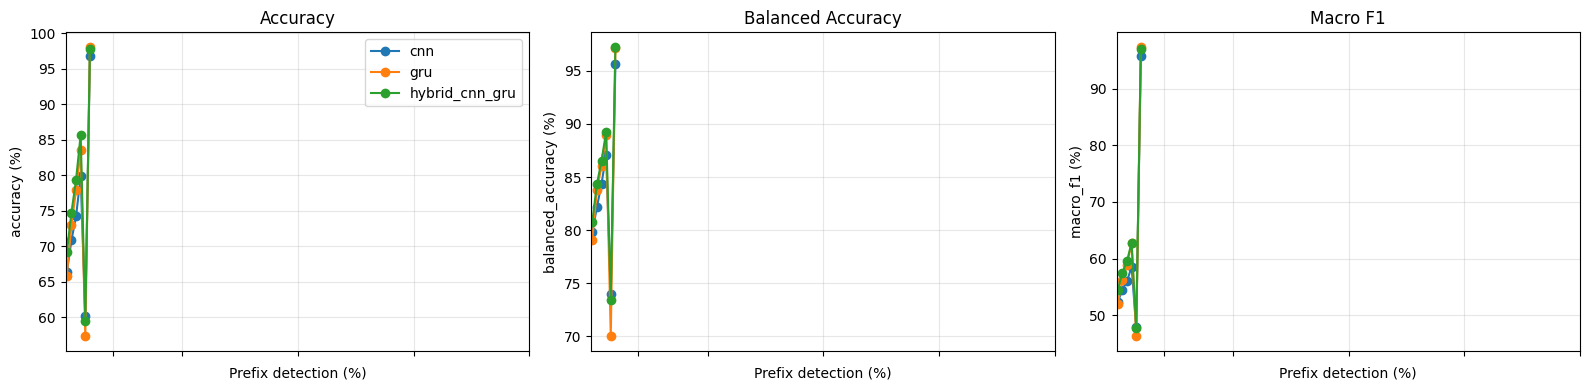

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for metric, axis in zip(('accuracy', 'balanced_accuracy', 'macro_f1'), axes):
    for model_name, group in summary.groupby('model'):
        group = group.sort_values('detection_count')
        axis.plot(group['detection_count'].astype(str), group[metric] * 100, marker='o', label=model_name)
    axis.set_xlabel('Prefix detection (%)')
    axis.set_ylabel(f'{metric} (%)')
    axis.set_title(metric.replace('_', ' ').title())
    axis.set_xticks([10, 25, 50, 75, 100])
    axis.grid(alpha=.3)
axes[0].legend()
fig.tight_layout()
fig.savefig(EARLY_DIR / 'early_classification_curves.png', dpi=150)
plt.show()


## 6. Confusion matrix pada prefix awal

Confusion matrix berikut membantu melihat apakah keunggulan awal model berasal dari pengenalan kelas tertentu atau dari dominasi kelas Periodic.

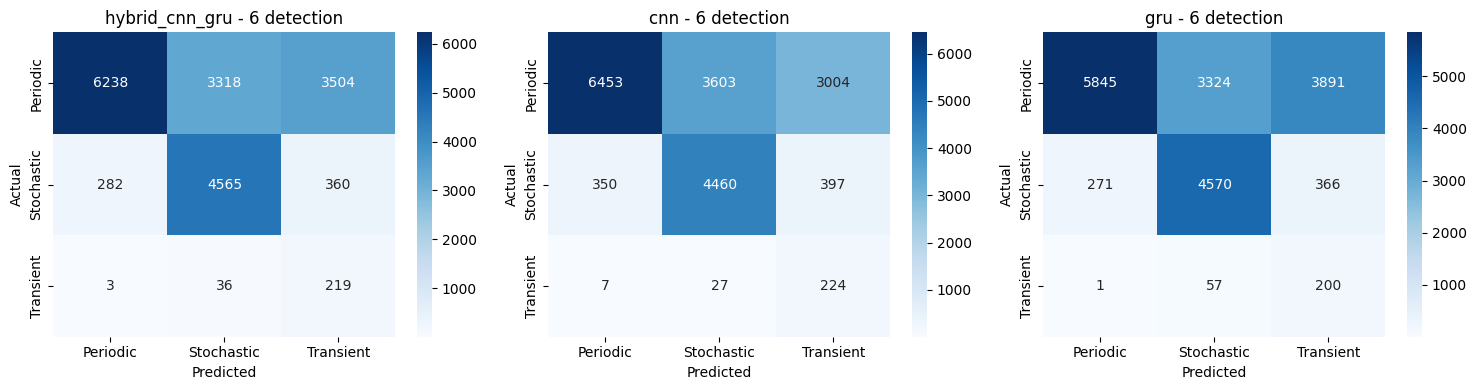

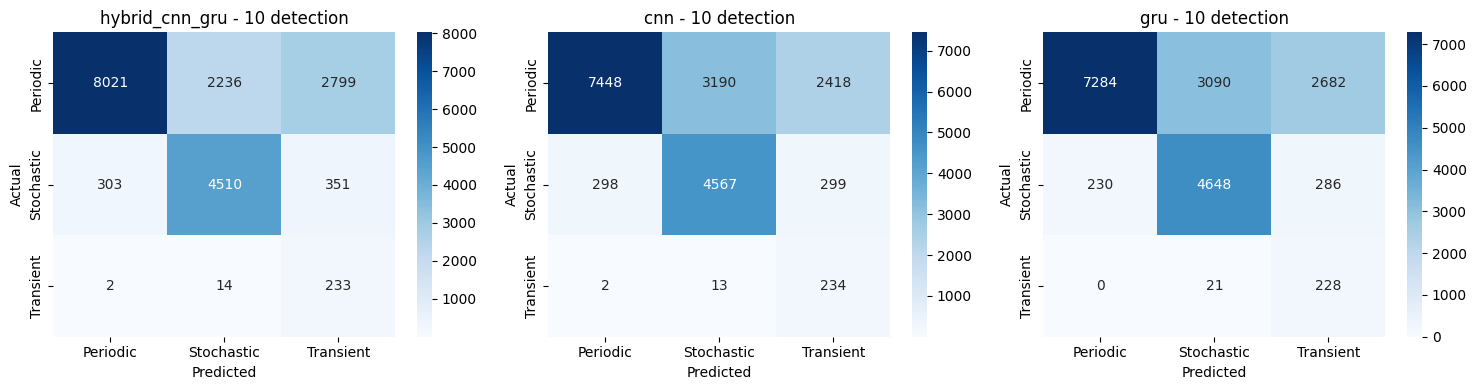

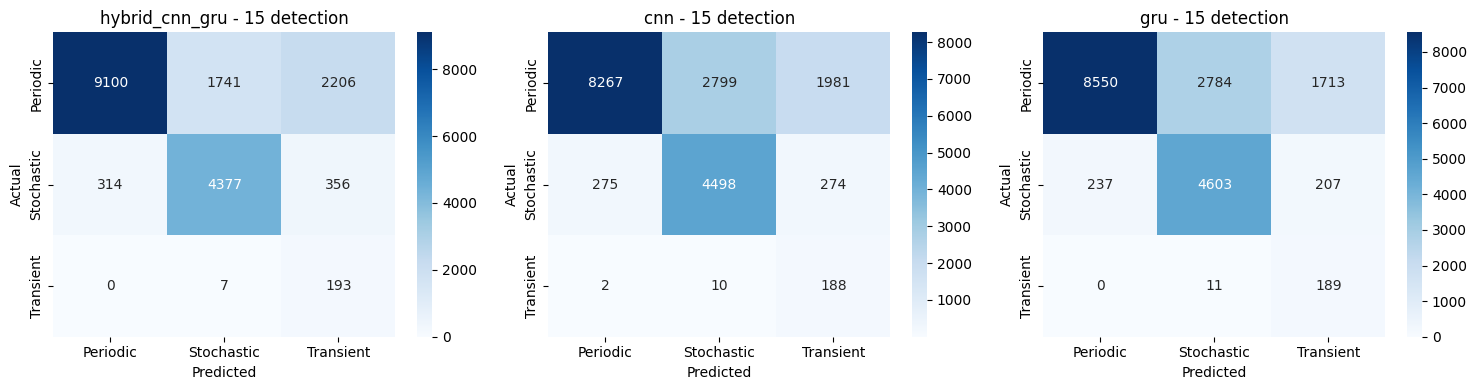

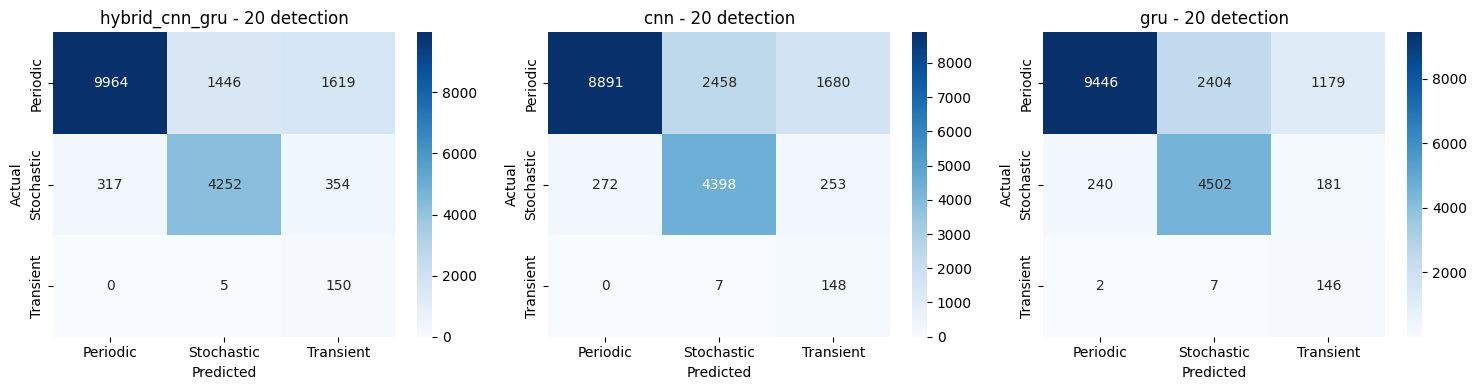

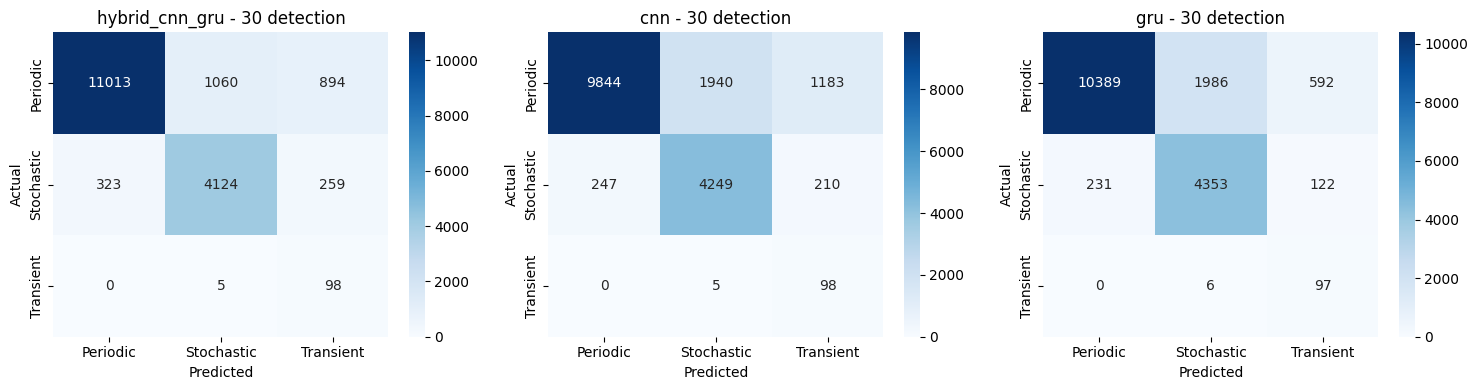

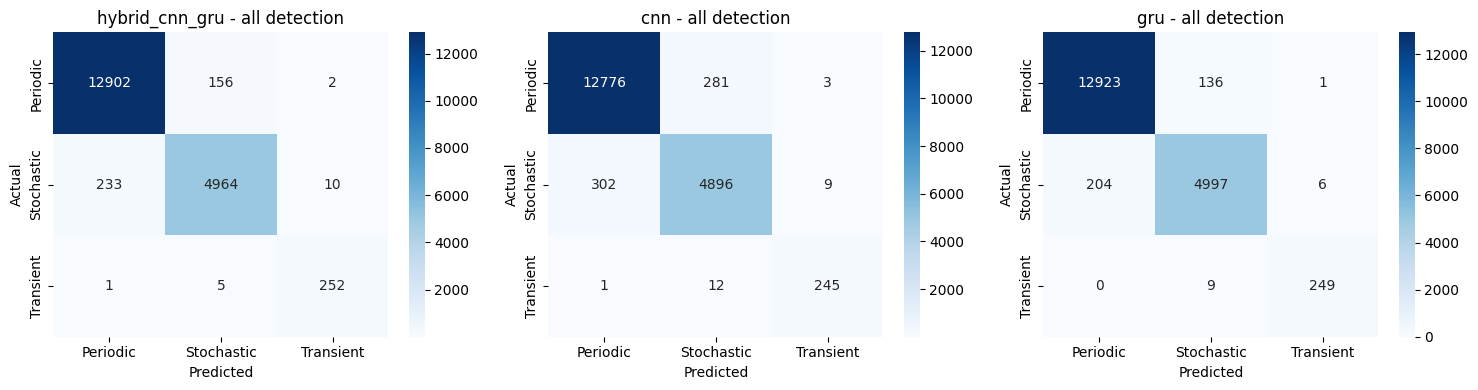

In [7]:
class_names = ['Periodic', 'Stochastic', 'Transient']
for detection_count in DETECTION_COUNTS:
    key = 'all' if detection_count is None else str(detection_count)
    fig, axes = plt.subplots(1, len(models), figsize=(15, 4))
    for axis, (model_name, results) in zip(axes, prefix_results.items()):
        sns.heatmap(
            results[key]['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axis,
        )
        axis.set_title(f'{model_name} - {key} detection')
        axis.set_xlabel('Predicted')
        axis.set_ylabel('Actual')
    fig.tight_layout()
    filename_key = 'all' if detection_count is None else str(detection_count)
    fig.savefig(EARLY_DIR / f'confusion_matrix_detection_{filename_key}.png', dpi=150)
    plt.show()


## Interpretasi yang diuji

Hipotesis eksperimen adalah Hybrid CNN-GRU dapat lebih kompetitif pada prefix pendek karena CNN memproses pola lokal seperti `local_slope` dan `delta_magnitude` sebelum GRU membangun konteks sequence. Hasil tetap harus ditentukan dari macro-F1 dan balanced accuracy per prefix, bukan dari dugaan arsitektur. Notebook ini adalah single-seed evaluation dan tidak mengubah checkpoint training.